# Iris Dataset Analysis

## Project Overview
This project explores the Iris flower dataset using Exploratory Data Analysis (EDA) and Machine Learning.

## Objectives
- Explore and understand the Iris dataset.
- Visualize flower measurements.
- Train Logistic Regression and KNN models.
- Compare model accuracy and performance.

## Technologies Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("iris.csv")

print(df.head())

   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa


Index(['sepal_length', 'sepal_width', 'petal_length', 'petal_width',
       'species'],
      dtype='str')
First Five Rows:
   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa

Dataset Shape:
(150, 5)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 7.2 KB

St

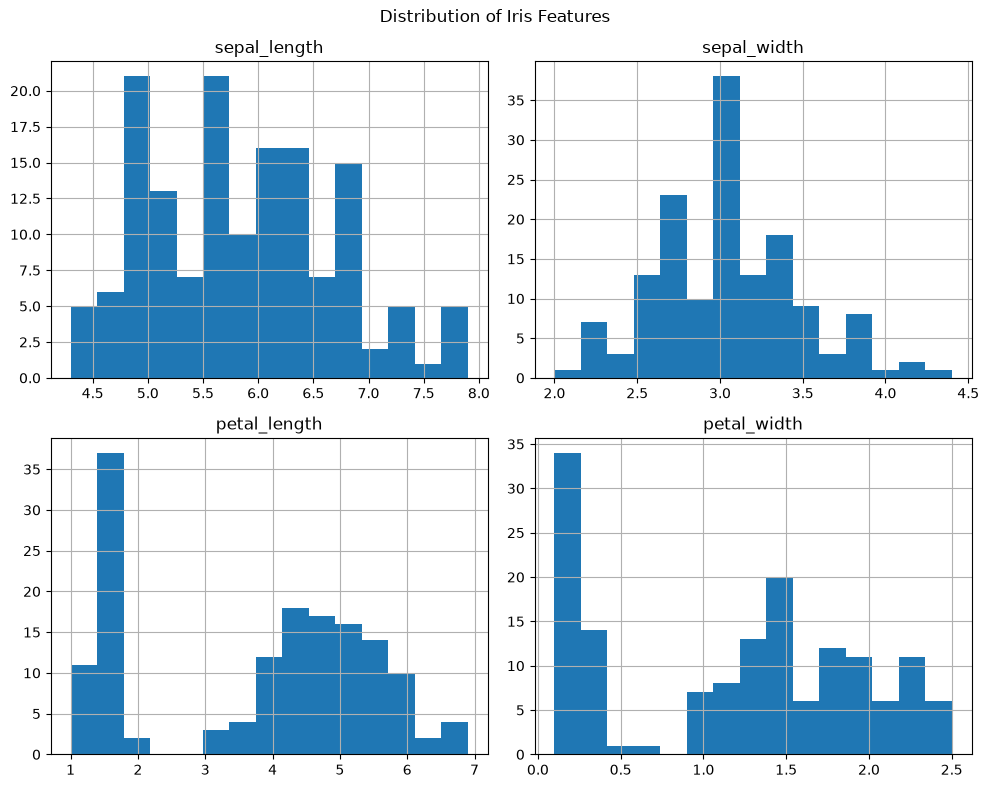

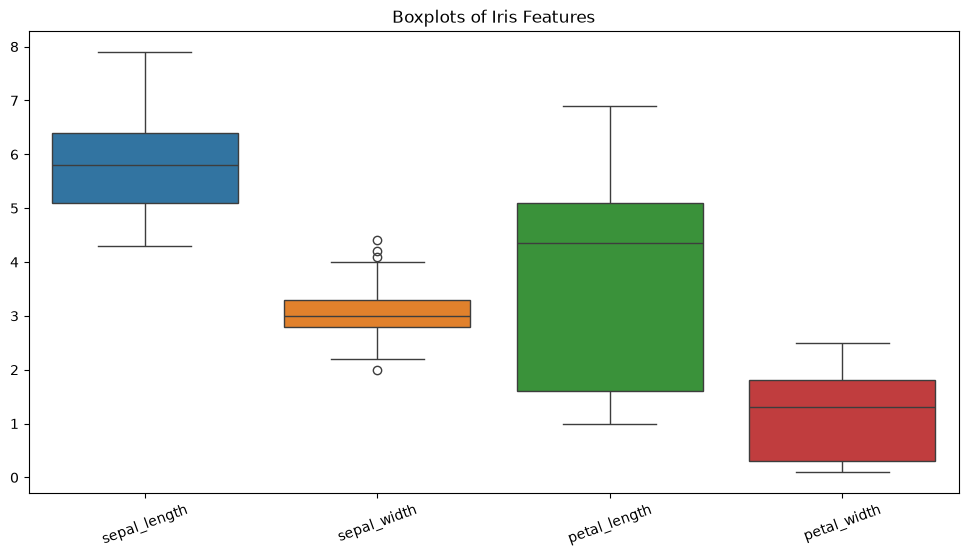

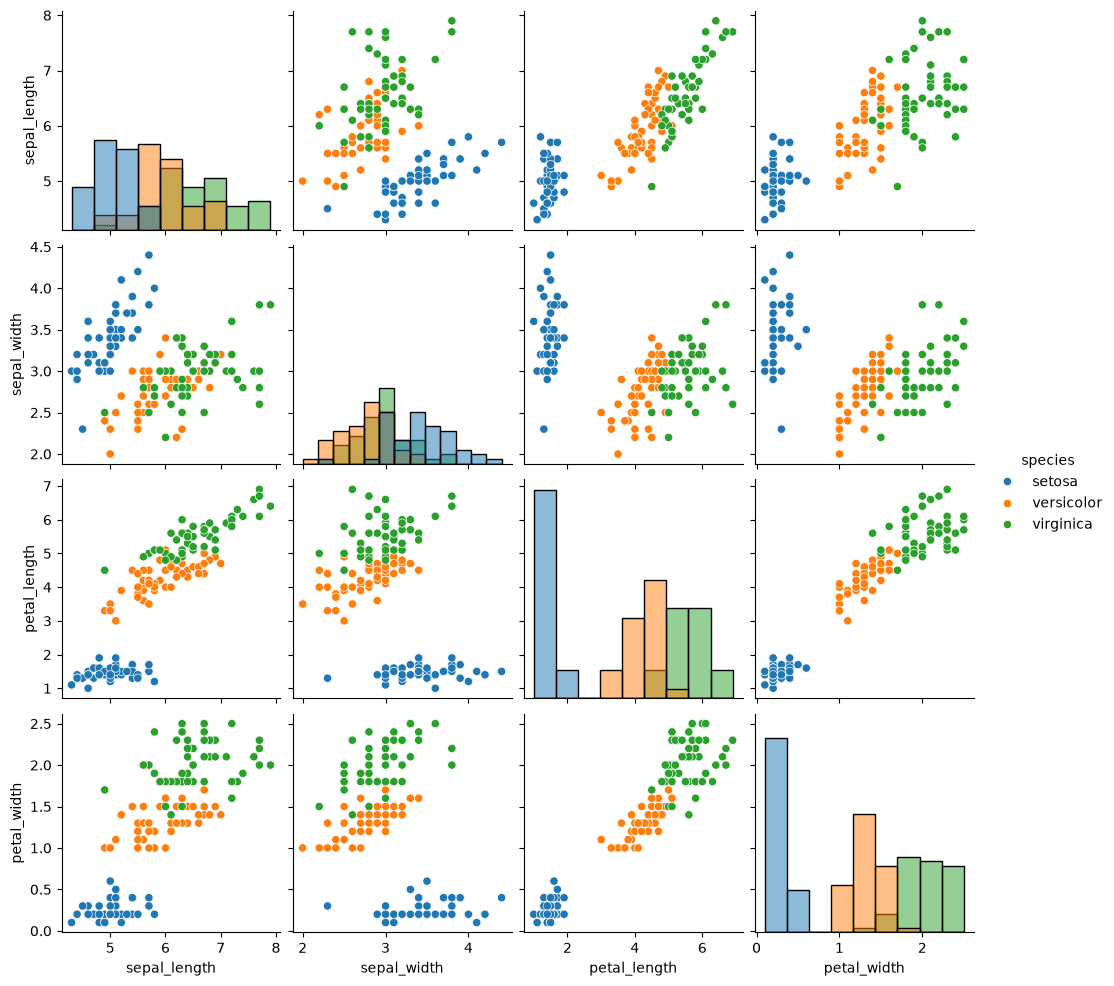

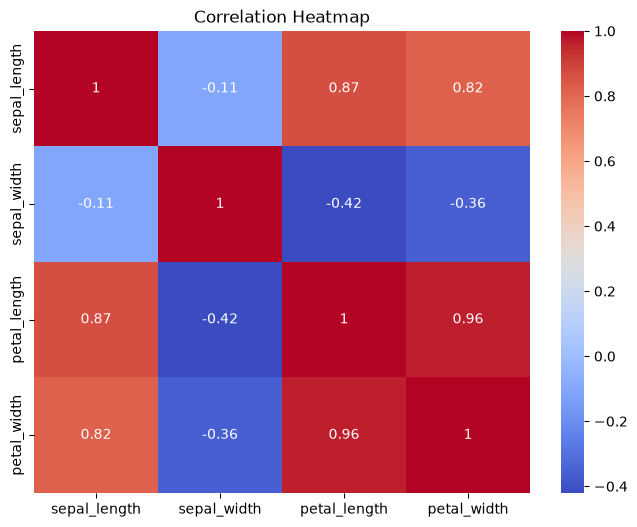


EDA Completed Successfully!


In [9]:
# ==========================================
# IRIS DATASET ANALYSIS
# PART 1: DATA LOADING, EDA & VISUALIZATION
# ==========================================

# 1. Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris

# 2. Load Iris Dataset
df = pd.read_csv("iris.csv")
print(df.columns)

# 3. Display Dataset
print("First Five Rows:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
df.info()

# 4. Statistical Summary
print("\nStatistical Summary:")
print(df.describe())

# 5. Check Missing Values
print("\nMissing Values:")
print(df.isnull().sum())

# 6. Check Duplicate Values
print("\nDuplicate Rows:")
print(df.duplicated().sum())

# 7. Species Distribution
print("\nSpecies Distribution:")
print(df["species"].value_counts())

# 8. Histogram
df.iloc[:, :4].hist(figsize=(10, 8), bins=15)
plt.suptitle("Distribution of Iris Features")
plt.tight_layout()
plt.show()

# 9. Boxplots
plt.figure(figsize=(12, 6))
sns.boxplot(data=df.iloc[:, :4])
plt.title("Boxplots of Iris Features")
plt.xticks(rotation=20)
plt.show()

# 10. Pairplot
sns.pairplot(
    df,
    hue="species",
    diag_kind="hist"
)
plt.show()

# 11. Correlation Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(
    df.iloc[:, :4].corr(),
    annot=True,
    cmap="coolwarm"
)
plt.title("Correlation Heatmap")
plt.show()

print("\nEDA Completed Successfully!")


Training Data: (120, 4)
Testing Data: (30, 4)

Logistic Regression Accuracy: 93.33 %
KNN Accuracy: 93.33 %

Logistic Regression Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


KNN Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



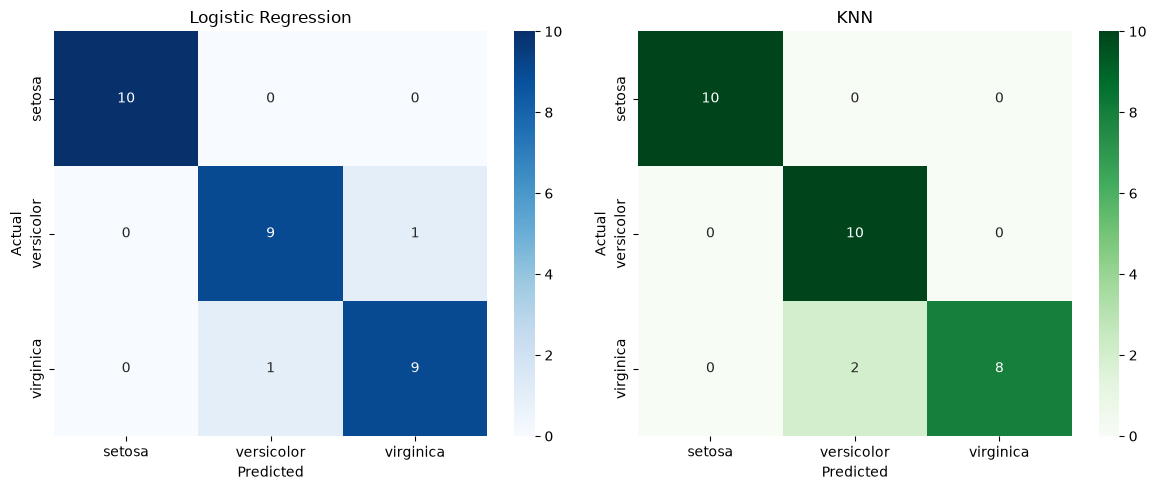


Model Comparison:
                 Model  Accuracy
0  Logistic Regression  0.933333
1                  KNN  0.933333

Predicted Flower Species: setosa

Machine Learning Completed Successfully!


In [10]:
# ==========================================
# PART 2: MACHINE LEARNING
# LOGISTIC REGRESSION & KNN
# ==========================================

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# 1. Separate Features and Target
feature_columns = [
    "sepal_length",
    "sepal_width",
    "petal_length",
    "petal_width"
]

X = df[feature_columns]
y = df["species"]

# 2. Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

# 3. Create Models
logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

knn_model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

# 4. Train Models
logistic_model.fit(X_train, y_train)
knn_model.fit(X_train, y_train)

# 5. Make Predictions
logistic_predictions = logistic_model.predict(X_test)
knn_predictions = knn_model.predict(X_test)

# 6. Calculate Accuracy
logistic_accuracy = accuracy_score(y_test, logistic_predictions)
knn_accuracy = accuracy_score(y_test, knn_predictions)

print("\nLogistic Regression Accuracy:",
      round(logistic_accuracy * 100, 2), "%")

print("KNN Accuracy:",
      round(knn_accuracy * 100, 2), "%")

# 7. Classification Reports
species_names = sorted(y.unique())

print("\nLogistic Regression Report:")
print(classification_report(
    y_test, logistic_predictions,
    target_names=species_names
))

print("\nKNN Classification Report:")
print(classification_report(
    y_test, knn_predictions,
    target_names=species_names
))

# 8. Confusion Matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(
    confusion_matrix(y_test, logistic_predictions),
    annot=True, fmt="d", cmap="Blues",
    xticklabels=species_names,
    yticklabels=species_names,
    ax=axes[0]
)

axes[0].set_title("Logistic Regression")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(
    confusion_matrix(y_test, knn_predictions),
    annot=True, fmt="d", cmap="Greens",
    xticklabels=species_names,
    yticklabels=species_names,
    ax=axes[1]
)

axes[1].set_title("KNN")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

# 9. Model Comparison
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "KNN"],
    "Accuracy": [logistic_accuracy, knn_accuracy]
})

print("\nModel Comparison:")
print(comparison)

# 10. New Flower Prediction
sample = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=feature_columns
)

prediction = logistic_model.predict(sample)

print("\nPredicted Flower Species:", prediction[0])

print("\nMachine Learning Completed Successfully!")

In [11]:
print(df["species"].value_counts())

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [12]:
print(df.columns.tolist())

['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']


In [14]:
import os
print(os.getcwd())

C:\Users\PC
